In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
CLEAN, IMG = ROOT / "data" / "clean", ROOT / "images"
IMG.mkdir(exist_ok=True)

rem = pd.read_csv(CLEAN / "remitter_clean.csv")
nat = pd.read_csv(CLEAN / "national_monthly.csv")

# ---------- ASSUMPTIONS (inhe badal ke dekho) ----------
LAST_MONTHS = ["2026-06", "2026-07", "2026-08"]   # recent 3 full months, taaki noise kam ho
PERMANENT_LOSS_SHARE = 0.25     # ASSUMPTION: failed payments ka kitna hissa kabhi complete nahi hota
BENCHMARK_PCTL = 0.25           # target = technical declines mein best quartile wala bank
MIN_VOLUME_MN = 100             # sirf itni volume wale banks se compare karo
BANK = "CANARA BANK"            # kisi bhi bank_key se badal sakte ho

# ---------- REAL inputs ----------
nat["month"] = nat.month_start.str[:7]
ticket = nat[nat.month.isin(LAST_MONTHS)].avg_ticket_rs.mean()          # Rs per txn (real NPCI)
r = rem[rem.month.isin(LAST_MONTHS)].copy()
r["td_txn"], r["bd_txn"] = r.volume_mn * r.td_pct / 100, r.volume_mn * r.bd_pct / 100
b = r.groupby("bank_key").agg(vol=("volume_mn", "sum"), td=("td_txn", "sum"), bd=("bd_txn", "sum"))
b["monthly_vol_mn"] = b.vol / len(LAST_MONTHS)
b["td_pct"], b["bd_pct"] = 100 * b.td / b.vol, 100 * b.bd / b.vol
print("avg ticket Rs %.0f | banks: %d" % (ticket, len(b)))

avg ticket Rs 1251 | banks: 50


In [2]:
big = b[b.monthly_vol_mn >= MIN_VOLUME_MN]
bench = big.td_pct.quantile(BENCHMARK_PCTL)
b["excess_td_pct"] = (b.td_pct - bench).clip(lower=0)
b["avoidable_fail_mn_yr"] = b.monthly_vol_mn * 12 * b.excess_td_pct / 100                # failed attempts jo bach sakte hain (Mn/saal)
b["value_rs_cr_yr"] = b.avoidable_fail_mn_yr * PERMANENT_LOSS_SHARE * ticket / 10        # Mn x Rs / 10 = Rs crore
print("benchmark technical decline: %.3f%%" % bench)

top = b.sort_values("value_rs_cr_yr", ascending=False)
out = top[["monthly_vol_mn", "td_pct", "excess_td_pct", "avoidable_fail_mn_yr", "value_rs_cr_yr"]].round(3)
out.to_csv(ROOT / "data" / "impact_by_bank.csv")
print("\nall banks together: %.1f Mn failed payments/yr, Rs %.0f crore/yr" % (b.avoidable_fail_mn_yr.sum(), b.value_rs_cr_yr.sum()))
out.head(10)

benchmark technical decline: 0.109%

all banks together: 653.0 Mn failed payments/yr, Rs 20422 crore/yr


,monthly_vol_mn,td_pct,excess_td_pct,avoidable_fail_mn_yr,value_rs_cr_yr
bank_key,,,,,
STATE BANK OF INDIA,6594.758,0.339,0.230,181.737,5683.719
CENTRAL BANK OF INDIA,453.142,1.581,1.472,80.041,2503.230
PUNJAB NATIONAL BANK,1465.540,0.541,0.432,75.893,2373.507
CANARA BANK,1239.658,0.353,0.244,36.236,1133.249
BANK OF BARODA,1766.365,0.276,0.167,35.363,1105.964
BARODA U P BANK,101.627,2.649,2.540,30.978,968.817
TELANGANA GRAMEENA BANK,58.106,3.509,3.400,23.708,741.448
BANK OF INDIA,764.012,0.368,0.259,23.701,741.240
RAJASTHAN MARUDHARA GRAMIN BANK,74.174,2.771,2.662,23.695,741.063


CANARA BANK: monthly volume 1240 Mn | technical decline 0.353% | business decline 9.17%
Rs crore/year recovered by cutting business declines:


,BD cut 5%,BD cut 10%,BD cut 15%
15% never completed,1280.0,2561.0,3841.0
25% never completed,2134.0,4268.0,6402.0
35% never completed,2988.0,5975.0,8963.0


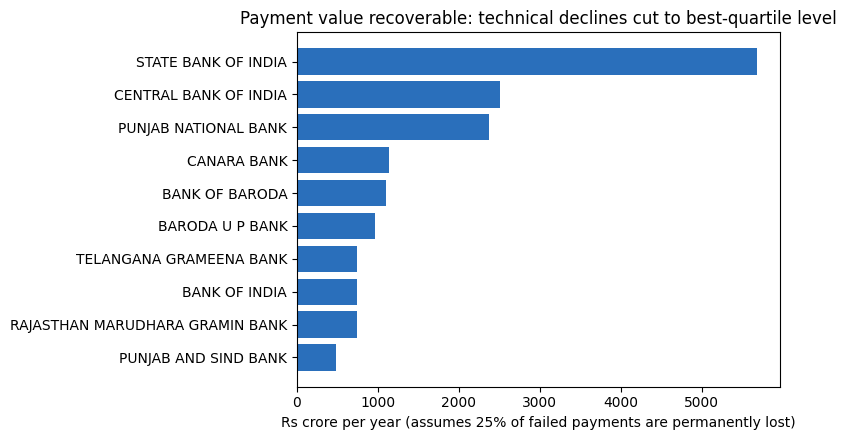

In [3]:
x = b.loc[BANK]
print("%s: monthly volume %.0f Mn | technical decline %.3f%% | business decline %.2f%%" % (BANK, x.monthly_vol_mn, x.td_pct, x.bd_pct))

losses, cuts = (0.15, 0.25, 0.35), (0.05, 0.10, 0.15)
grid = pd.DataFrame(index=[f"{int(s*100)}% never completed" for s in losses],
                    columns=[f"BD cut {int(c*100)}%" for c in cuts], dtype=float)
for i, s in enumerate(losses):
    for j, c in enumerate(cuts):
        saved_mn = x.monthly_vol_mn * 12 * x.bd_pct / 100 * c
        grid.iloc[i, j] = saved_mn * s * ticket / 10
print("Rs crore/year recovered by cutting business declines:")
display(grid.round(0))

t = top.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(t.index, t.value_rs_cr_yr, color="#2a6fbb")
ax.set_xlabel("Rs crore per year (assumes %d%% of failed payments are permanently lost)" % (PERMANENT_LOSS_SHARE * 100))
ax.set_title("Payment value recoverable: technical declines cut to best-quartile level")
fig.tight_layout(); fig.savefig(IMG / "05_impact_by_bank.png"); plt.show()